<a href="https://colab.research.google.com/github/Trumpibeabuchi/techcrush-c9-group5-attrition/blob/main/notebooks/EMPLOYEE_ATTRITION_PREDICTION.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Employee Attrition Prediction — Group 5_C9

Which employees are likely to leave, and what is linked to leaving?
Data: IBM HR Analytics Employee Attrition (fictional, 1,470 employees, 16% left).
Full context, team and how to run: see the repository
[README](https://github.com/Trumpibeabuchi/techcrush-c9-group5-attrition#readme).

**Hypotheses (written before the analysis):**
H1 overtime · H2 pay · H3 tenure/age · H4 satisfaction · H5 travel · H6 job role ·
H7 gender/education (control)

**Note:** units are not documented, and the data is fictional, so results are
compared in relative terms.

## 1. Setup

In [1]:
# Import libraries for data manipulation

import pandas as pd
import numpy as np

# Import libraries for data visualization

import matplotlib.pyplot as plt
import seaborn as sns

# Import libraries for data preprocessing

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Import machine learning algorithms

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Import evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# Import cross-validation tools

from sklearn.model_selection import cross_validate, StratifiedKFold

# Import tools for saving models

import joblib

# Other libraries

import os
import warnings

warnings.filterwarnings("ignore")

# Set visualization style

sns.set_theme(style="whitegrid")

# Display all columns

pd.set_option("display.max_columns", None)

# Folder for exported charts (used in the report and slides)

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

print("All libraries imported successfully.")

All libraries imported successfully.


## 2. Data loading

The CSV is read from the `data/` folder of this repository, so the notebook
runs end to end without uploading anything.

In [2]:
# Load the dataset directly from the team GitHub repository.
# This makes the notebook reproducible: 'Run all' works with no manual upload.

DATA_URL = (
    "https://raw.githubusercontent.com/Trumpibeabuchi/techcrush-c9-group5-attrition/"
    "main/data/WA_Fn-UseC_-HR-Employee-Attrition.csv"
)

df = pd.read_csv(DATA_URL)

# Display the first five records

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


In [3]:
# Dataset dimensions

n_rows, n_cols = df.shape

print(f"The dataset has {n_rows:,} rows (employees) and {n_cols} columns.")

The dataset has 1,470 rows (employees) and 35 columns.


In [4]:
# Display dataset information

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [5]:
# Statistical summary of numerical variables

df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,MonthlyRate,NumCompaniesWorked,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,2.728571,6502.931293,14313.103401,2.693197,15.209524,3.153741,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,1.102846,4707.956783,7117.786044,2.498009,3.659938,0.360824,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,1.000000,1009.000000,2094.000000,0.000000,11.000000,3.000000,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,2.000000,2911.000000,8047.000000,1.000000,12.000000,3.000000,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,3.000000,4919.000000,14235.500000,2.000000,14.000000,3.000000,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,4.000000,8379.000000,20461.500000,4.000000,18.000000,3.000000,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,4.000000,19999.000000,26999.000000,9.000000,25.000000,4.000000,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [6]:
# Summary of categorical variables

df.describe(include="object")

,Attrition,BusinessTravel,Department,EducationField,Gender,JobRole,MaritalStatus,Over18,OverTime
count,1470,1470,1470,1470,1470,1470,1470,1470,1470
unique,2,3,3,6,2,9,3,1,2
top,No,Travel_Rarely,Research & Development,Life Sciences,Male,Sales Executive,Married,Y,No
freq,1233,1043,961,606,882,326,673,1470,1054


## 3. Data Quality Assessment

Before performing exploratory data analysis, the dataset
must be examined for potential data quality issues.

This section investigates:

1. Missing values.
2. Duplicate records.
3. Data types.
4. Unique values.
5. Constant columns.

These checks help determine whether the dataset requires
additional cleaning before model development.

In [7]:
# Check for missing values
# (df.info() above already shows 1,470 non-null in every column)

print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [8]:
# Check duplicate records

duplicates = df.duplicated().sum()

print("Number of duplicate records:", duplicates)

Number of duplicate records: 0


In [9]:
# Examine the number of unique values in each column

unique_values = df.nunique()

unique_values.sort_values()

EmployeeCount                  1
Over18                         1
StandardHours                  1
Attrition                      2
OverTime                       2
PerformanceRating              2
Gender                         2
BusinessTravel                 3
Department                     3
MaritalStatus                  3
RelationshipSatisfaction       4
StockOptionLevel               4
JobSatisfaction                4
EnvironmentSatisfaction        4
JobInvolvement                 4
WorkLifeBalance                4
Education                      5
JobLevel                       5
EducationField                 6
TrainingTimesLastYear          7
JobRole                        9
NumCompaniesWorked            10
PercentSalaryHike             15
YearsSinceLastPromotion       16
YearsWithCurrManager          18
YearsInCurrentRole            19
DistanceFromHome              29
YearsAtCompany                37
TotalWorkingYears             40
Age                           43
HourlyRate

In [10]:
# Identify columns with only one unique value

constant_columns = [
    column for column in df.columns
    if df[column].nunique() == 1
]

print("Constant Columns:")

print(constant_columns)

Constant Columns:
['EmployeeCount', 'Over18', 'StandardHours']


### Data Quality Assessment Findings

The dataset contains 1,470 employee records and 35 columns.

The initial examination indicates that the dataset contains
no missing values.

Duplicate records will also be examined to determine whether
any observations need to be removed.

The constant columns will be considered during feature
selection because they do not provide useful information
for distinguishing between employees who leave and those
who stay.

The data types will also be examined to ensure that
numerical and categorical variables are processed correctly.

## 4. Exploratory Data Analysis

Exploratory Data Analysis (EDA) involves examining and
visualising the dataset to understand its characteristics,
relationships and underlying patterns.

The purpose of this section is to identify possible factors
associated with employee attrition.

The analysis will examine:

1. Employee attrition distribution.
2. Employee age distribution.
3. Attrition by department.
4. Attrition by gender.
5. Attrition by overtime.
6. Attrition by job satisfaction.
7. Attrition by business travel.
8. Monthly income distribution.
9. Years at company.
10. Correlation between numerical variables.

### 4.1 Attrition distribution

In [11]:
# Examine the distribution of the target variable

attrition_counts = df["Attrition"].value_counts()

print(attrition_counts)

print("\nPercentage Distribution:")

print(
    df["Attrition"].value_counts(normalize=True) * 100
)

Attrition
No     1233
Yes     237
Name: count, dtype: int64

Percentage Distribution:
Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64


**Visualisation**

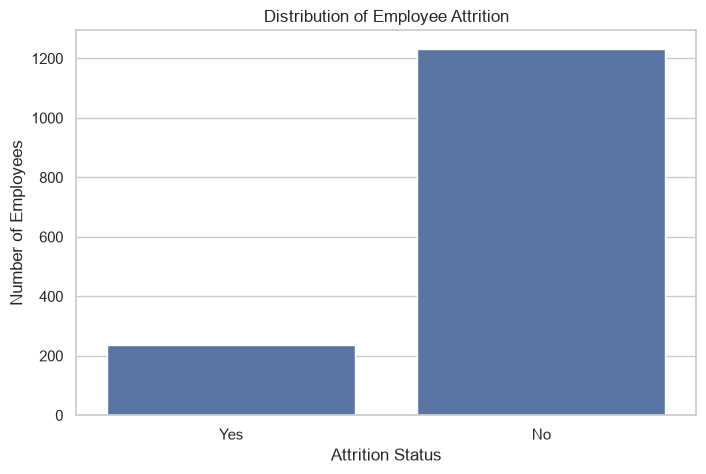

In [12]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Attrition"
)

plt.title("Distribution of Employee Attrition")

plt.xlabel("Attrition Status")

plt.ylabel("Number of Employees")

plt.savefig(
    f"{FIG_DIR}/attrition_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 4.2 Employee age distribution

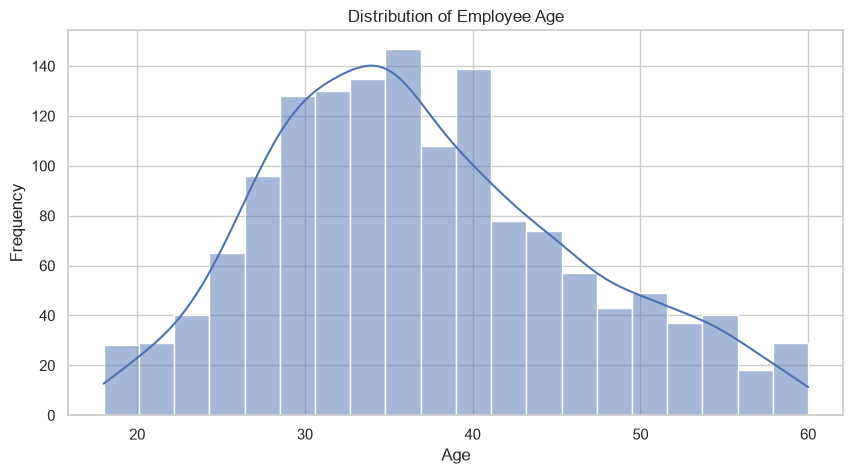

In [13]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Age",
    bins=20,
    kde=True
)

plt.title("Distribution of Employee Age")

plt.xlabel("Age")

plt.ylabel("Frequency")

plt.savefig(
    f"{FIG_DIR}/age_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

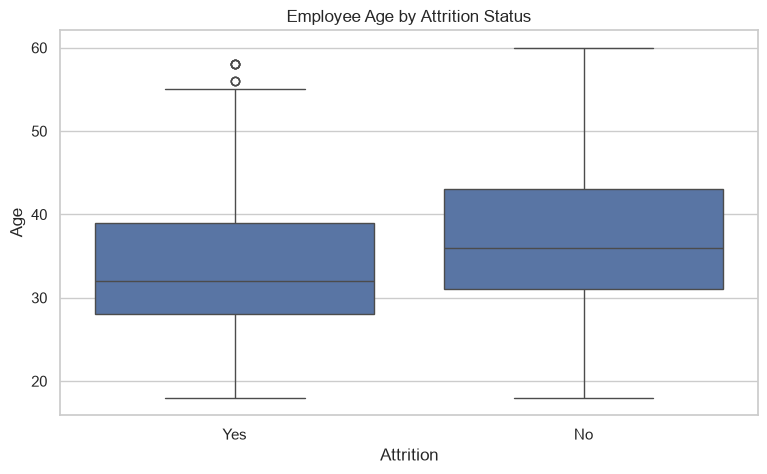

In [14]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Attrition",
    y="Age"
)

plt.title("Employee Age by Attrition Status")

plt.xlabel("Attrition")

plt.ylabel("Age")

plt.savefig(
    f"{FIG_DIR}/age_by_attrition.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()